# 02 · Re-running the thesis protocol

The original thesis code was lost. Before trusting the rebuild, I re-ran the thesis' own protocol (success as positive class, the original hyper-parameters, 5x2 CV, seed 42) and compared every re-computed number with the printed one. The heavy lifting is done by `fairpath reproduce-thesis`; this notebook reads its output.

In [1]:
import json, warnings
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
warnings.filterwarnings("ignore")
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
REPORTS = ROOT / "reports"
pd.set_option("display.precision", 3)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True,
                     "grid.color": "#e1e0d9", "font.size": 10})
BLUE, ORANGE, AQUA = "#2a78d6", "#eb6834", "#1baf7a"
rep = json.loads((REPORTS / "thesis_reproduction.json").read_text())
comp = pd.DataFrame(rep["comparison"])
print(rep["note"])
comp.groupby(["table", "status"]).size().unstack(fill_value=0)

Thesis protocol: success = positive class, aware models, thesis hyper-parameters, 5x2 RepeatedStratifiedKFold (seed 42). Thesis Table 6.1 used 5x1 folds, so small differences there are expected.


status,close,differs,match
table,,,
5.1,1,0,31
6.1 (|SPD|),8,7,9
noise floor,0,0,2


In [2]:
comp[comp.table == "5.1"].pivot_table(index=["dataset", "model"], columns="metric", values="diff").round(3)

metric                              AUC  Accuracy   F1  Macro_F1
dataset     model                                               
dropout     dummy_most_frequent     0.0     0.000  0.0     0.000
            hist_gradient_boosting  0.0     0.003  0.0     0.003
            logistic_regression     0.0     0.000  0.0     0.000
            random_forest           0.0     0.000  0.0     0.001
student_mat dummy_most_frequent     0.0     0.000  0.0     0.000
            hist_gradient_boosting  0.0     0.000  0.0     0.007
            logistic_regression     0.0     0.000  0.0     0.002
            random_forest           0.0     0.000  0.0    -0.001

Text(0.0, 1.0, 'Thesis vs re-run')

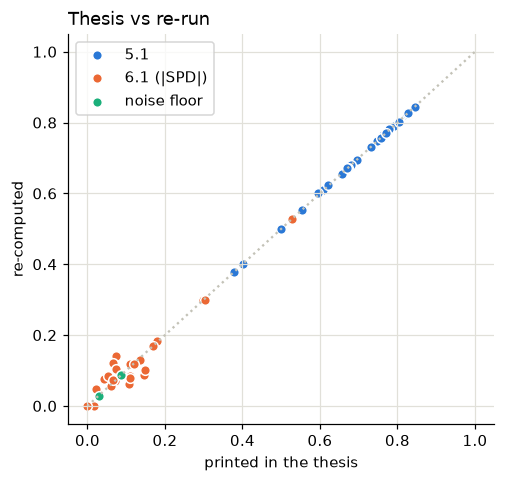

In [3]:
fig, ax = plt.subplots(figsize=(5, 4.6))
ax.plot([0, 1], [0, 1], ls=":", color="#c3c2b7")
for table, color in [("5.1", BLUE), ("6.1 (|SPD|)", ORANGE), ("noise floor", AQUA)]:
    t = comp[comp.table == table]
    ax.scatter(t.thesis, t.reproduced, color=color, label=table, edgecolor="white", s=40)
ax.set_xlabel("printed in the thesis"); ax.set_ylabel("re-computed"); ax.legend(); ax.set_title("Thesis vs re-run", loc="left")

Performance numbers come back almost exactly. The post-processing rows of Table 6.1 move more, because the thesis ran that table with five folds and a coarse threshold grid on very small validation slices. Let me show how unstable those cells are across folds:

In [4]:
res = rep["results"]["student_mat"]["summary"]
s = pd.DataFrame(res)
s[s.model.isin(["logistic_regression", "random_forest", "hist_gradient_boosting"])][["model", "condition", "SPD_mean", "SPD_std", "F1_mean", "F1_std"]]

,model,condition,SPD_mean,SPD_std,F1_mean,F1_std
2,hist_gradient_boosting,baseline,0.084,0.071,0.770,0.026
3,hist_gradient_boosting,combined,0.101,0.083,0.787,0.056
4,hist_gradient_boosting,post,0.103,0.083,0.786,0.045
5,hist_gradient_boosting,pre,0.079,0.058,0.774,0.024
6,logistic_regression,baseline,0.168,0.099,0.732,0.039
7,logistic_regression,combined,0.062,0.053,0.510,0.320
8,logistic_regression,post,0.088,0.095,0.607,0.276
9,logistic_regression,pre,0.119,0.084,0.728,0.036
10,random_forest,baseline,0.055,0.031,0.804,0.029
11,random_forest,combined,0.000,0.000,0.803,0.000


For student-mat the fold-to-fold standard deviation of |SPD| is about as large as the mean, which is RQ3 in one table: a re-run with different folds can easily move a post-processing cell by several hundredths. The corrections to the thesis text that came out of this exercise are listed in `docs/REPRODUCIBILITY.md`.